# E1 · Diagnóstico y necesidades · Aguas Andinas

**Grupo Aguas Andinas:** Byron Caices, Bastián Brito, Benjamín Sepúlveda, José Marin · Visualización de Datos 2026 S2 · Prof. Viktor Tapia
*Datos y metas 100% simulados con fines docentes; no representan instalaciones ni resultados reales de la empresa. Fechas en UTC.*

Este notebook se ejecuta **desde cero** con los tres lotes de telemetría y las tablas complementarias: verifica los datos originales y recalcula cada resultado. El documento de síntesis es `Diagnostico.pdf` (4 páginas).

**Decisión que apoya:** priorizar tres sectores para inspección considerando continuidad, diferencia de volúmenes, energía y confiabilidad de la medición, separando la evidencia operacional de la incertidumbre de los sensores. No se infiere potabilidad, cumplimiento regulatorio ni causalidad.

**Cómo ejecutar:** desde la carpeta `E1/`, con el entorno de `requirements.txt` (versiones en `versiones_probadas.txt`).

| Sección | Contenido | Origen |
|---|---|---|
| 1 | Carga y verificación de originales | `comun.py` |
| 2 | Audiencias, preguntas e inventario | T1 |
| 3 | Diccionario y contratos de datos | T1 |
| 4 | Calidad por lote y segmento | T2 (`T2_reglas.py`) |
| 5 | Cobertura y continuidad con límites 0/60 | T3 (`T3_cobertura.py`) |
| 6 | Análisis exploratorio de negocio (a–e) | T4 (`T4_eda.py`) |
| 7 | Costo de energía por m³ | T4 |
| 8 | KPI y métricas de calidad | T4 + T2 |
| 9 | Ranking de inspección | T2 + T3 + T4 |
| 10 | Verificación cruzada de cifras | T5 |

## 1. Carga y verificación de originales

In [1]:
import pandas as pd
from IPython.display import Image, display

import comun
import T2_reglas as rq
import T3_cobertura as t3
import T4_eda as t4

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLAS = comun.RAIZ / "E1" / "salidas" / "tablas"
FIGURAS = comun.RAIZ / "E1" / "salidas" / "figuras"

comun.verificar_hashes()                # los 8 CSV coinciden con el SHA-256 de metadatos.json
df, ctx, ev = t4.preparar()             # lee los 3 lotes como texto, parsea sin borrar filas y evalúa las reglas de T2
print(f"{len(df):,} filas de telemetría en {df.lote.nunique()} lotes; {len(ev)} reglas de calidad evaluadas".replace(",", "."))

253.404 filas de telemetría en 3 lotes; 22 reglas de calidad evaluadas


## 2. Audiencias, preguntas e inventario (T1)

- **Audiencia ejecutiva:** jefatura ficticia de operaciones y planificación; decide cómo asignar tres inspecciones y necesita prioridades comparables, cobertura e incertidumbre.
- **Audiencia operacional:** equipo ficticio de terreno, telemetría y mantenimiento; define qué revisar y qué evidencia levantar, con detalle por sector y semana.

| # | Pregunta medible | Cálculo | Acción que cambia |
|---|---|---|---|
| 1 | ¿Qué sectores podrían quedar bajo la meta de continuidad, considerando las horas desconocidas? | Continuidad ponderada por conexiones con límites 0/60 min vs. 99,5% | Priorizar si el límite superior queda bajo la meta |
| 2 | ¿Dónde es mayor la diferencia entre entrada y salida? | Σ(entrada − salida) / Σ entrada, en m³ | Revisar balance y medición |
| 3 | ¿Qué tres sectores combinan señales operacionales y medición confiable? | Ranking con y sin filtro de cobertura | Asignar inspecciones y su evidencia |

**Filas físicas, entidades y exposición** (tres medidas distintas que no se deben confundir):

In [2]:
meta = comun.META
inventario = pd.DataFrame([{"archivo": f["archivo"], "filas": f["filas"], "columnas": f["columnas"], "sha256": f["sha256"][:16] + "…"}
                           for f in meta["files"]])
exposicion = {lote: int((pd.Timestamp(fin, tz="UTC") - pd.Timestamp(ini, tz="UTC")) / pd.Timedelta(hours=1)) * 30
              for lote, (ini, fin) in rq.PERIODO_LOTE.items()}
recibidas = df.groupby("lote").size()
resumen_exposicion = pd.DataFrame({"filas_fisicas": recibidas, "sector_horas_esperadas": pd.Series(exposicion)}).loc[rq.LOTES]
resumen_exposicion["diferencia_esperadas_menos_recibidas"] = resumen_exposicion.sector_horas_esperadas - resumen_exposicion.filas_fisicas
print("Entidades: 30 sectores del catálogo · exposición total:", f"{sum(exposicion.values()):,}".replace(",", "."), "sector-horas")
display(inventario)
resumen_exposicion

Entidades: 30 sectores del catálogo · exposición total: 262.800 sector-horas


/var/folders/b5/cn2n5mh576j6jtfwl25p1rrc0000gn/T/ipykernel_38280/488634108.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  exposicion = {lote: int((pd.Timestamp(fin, tz="UTC") - pd.Timestamp(ini, tz="UTC")) / pd.Timedelta(hours=1)) * 30


,archivo,filas,columnas,sha256
0,datos/actualizacion/telemetria_horaria.csv,22432,11,16c591d7956a5c31…
1,datos/ampliacion/telemetria_horaria.csv,100000,11,0f95e0e2a8759837…
2,datos/base/telemetria_horaria.csv,130972,11,1e9edf220a71b49f…
3,datos/complementarios/metas_2025_ancho.csv,30,16,2ecbf487d1c7d61e…
4,datos/complementarios/sectores_historial.csv,60,7,e5eb2475a96725c6…
5,datos/complementarios/tarifas_energia.csv,150,3,5b972d095c557ffa…
6,datos/dimensiones/metas_ancho.csv,30,11,67ed256a92faa117…
7,datos/dimensiones/sectores.csv,30,5,ac9d03a7fbd69b17…


,filas_fisicas,sector_horas_esperadas,diferencia_esperadas_menos_recibidas
base,130972,130320,-652
actualizacion,22432,22320,-112
ampliacion,100000,110160,10160


En base y actualización llegan **más** filas que horas (652 y 112 copias exactas). En ago–dic llegan 100.000 filas para 110.160 sector-horas: **10.160 nunca llegaron**. Esta cifra corrige el "10.000" del notebook de trabajo de T1. Procedencia: paquete v2 del 2026-10-01, con semillas 20260924 y 20261004, datos 100% sintéticos.

## 3. Diccionario y contratos de datos (T1)

`diccionario_revisado.csv` documenta los 75 campos con tipo estadístico, escala, unidad, nulabilidad, clave y un **contrato verificable**. En la sección 4, T2 mide el cumplimiento de esos contratos.

In [3]:
dic = pd.read_csv(TABLAS / "diccionario_revisado.csv")
# Corrección de la consolidación: minutos_interrupcion solo toma valores enteros, así que es cuantitativa discreta.
dic.loc[dic.campo.eq("minutos_interrupcion"), "tipo_estadistico"] = "cuantitativa discreta"
assert (df["minutos_interrupcion"].dropna() % 1 == 0).all()
tel = dic[dic.archivo.eq("datos/ampliacion/telemetria_horaria.csv")]
tel[["campo", "tipo_estadistico", "escala", "unidad", "nulabilidad", "contrato"]]

,campo,tipo_estadistico,escala,unidad,nulabilidad,contrato
38,medicion_id,identificador,nominal,id de medición,No previsto; nulo indica defecto,Identificador único; no se promedia.
39,fecha,temporal,intervalo,fecha-hora UTC,No previsto; nulo indica defecto,Inicio de la hora de negocio; parseable y dent...
40,sector_id,identificador,nominal,id de sector,No previsto; nulo indica defecto,Debe existir en el catálogo; no se promedia.
41,volumen_entrada,cuantitativa continua,razón,m³ o L según unidad_volumen,Sí: falta de captura; contar como nulo,No negativo y numérico; convertir L a m³ divid...
42,volumen_salida,cuantitativa continua,razón,m³ o L según unidad_volumen,Sí: falta de captura; contar como nulo,No negativo y numérico; misma unidad que entra...
43,unidad_volumen,categórica nominal,nominal,categoría,No previsto; nulo indica defecto,m3 o L; otra unidad no se convierte.
44,presion_bar,cuantitativa continua,razón,bar,Sí: falta de captura; contar como nulo,Valor numérico no negativo; señal operacional ...
45,energia_kwh,cuantitativa continua,razón,kWh,Sí: falta de captura; contar como nulo,Energía no negativa; costo solo donde hay tarifa.
46,minutos_interrupcion,cuantitativa discreta,razón,minutos,Sí: falta de captura; contar como nulo,Número entre 0 y 60; 0 es una lectura observada.
47,modo_operacion,categórica nominal,nominal,categoría,No previsto; nulo indica defecto,Normalizar espacios y mayúsculas; valores espe...


## 4. Calidad por lote y segmento (T2)

Cada problema se mide con una regla con denominador propio y se clasifica como **defecto**, **extremo plausible** o **ausencia estructural**. Aquí no se limpia nada: el tratamiento propuesto es el plan de limpieza de la E2. El atraso de carga se mide con un umbral de 2 h ([D-01](decisiones.md)).

In [4]:
matriz = rq.matriz_reglas(df, ev, ctx)
tel_m = matriz[matriz.lote.isin(rq.LOTES)].assign(pct=lambda d: 100 * d.filas_fallidas / d.filas_evaluadas)
resumen_reglas = (tel_m.pivot_table(index=["regla_id", "clasificacion"], columns="lote", values="pct", sort=False)[rq.LOTES]
                  .round(3).reset_index())
resumen_reglas.insert(1, "regla", resumen_reglas.regla_id.map(rq.NOMBRE_CORTO))
resumen_reglas

lote,regla_id,regla,clasificacion,base,actualizacion,ampliacion
0,RQ-UNI-01,Copia exacta de fila,defecto,0.498,0.499,0.000
1,RQ-UNI-02,Clave con contenido distinto,defecto,0.000,0.000,0.000
2,RQ-UNI-03,Sector-hora repetida,defecto,0.000,0.000,0.000
3,RQ-VAL-01,Fecha imposible,defecto,0.100,0.098,0.200
4,RQ-VAL-02,Fecha dd/mm (recuperable),defecto,0.000,0.000,0.500
5,RQ-VAL-03,Fecha fuera del lote,defecto,0.000,0.000,0.000
6,RQ-VAL-04,Coma decimal (recuperable),defecto,0.000,0.000,0.600
7,RQ-VAL-05,Volumen con texto (PENDIENTE),defecto,0.000,0.000,0.256
8,RQ-VAL-06,Unidad desconocida,defecto,0.000,0.000,0.250
9,RQ-VAL-07,Volumen de entrada negativo,defecto,0.403,0.401,0.410


In [5]:
perfil = rq.perfil_calidad(df, ev)
print(f"perfil_calidad.csv: {len(perfil):,} filas (lote × segmento × campo)".replace(",", "."))
(perfil[perfil.segmento_tipo.eq("total")].pivot_table(index="campo", columns="lote", values=["pct_nulos", "pct_invalidos"], sort=False)
 .reindex(columns=rq.LOTES, level=1).round(3))

perfil_calidad.csv: 1.287 filas (lote × segmento × campo)


pct_nulos                          pct_invalidos                         
lote                      base actualizacion ampliacion          base actualizacion ampliacion
campo                                                                                         
medicion_id              0.000         0.000        0.0         0.498         0.499       0.00
fecha                    0.000         0.000        0.0         0.100         0.098       0.20
sector_id                0.000         0.000        0.0         0.202         0.201       0.30
volumen_entrada          0.999         0.994        2.2         0.399         0.397       0.65
volumen_salida           0.000         0.000        0.0         0.000         0.000       0.00
unidad_volumen           0.000         0.000        0.0         0.000         0.000       0.25
presion_bar              0.000         0.000        0.0         0.000         0.000       0.00
energia_kwh              0.000         0.000        0.0         0.000         0.000       0.00
minutos_interrupcion     0.000         0.000        0.0         0.000         0.000       0.35
modo_operacion           0.000         0.000        0.0         0.000         0.000       0.00
cargado_en               0.000         0.000        0.0         0.000         0.000       0.30

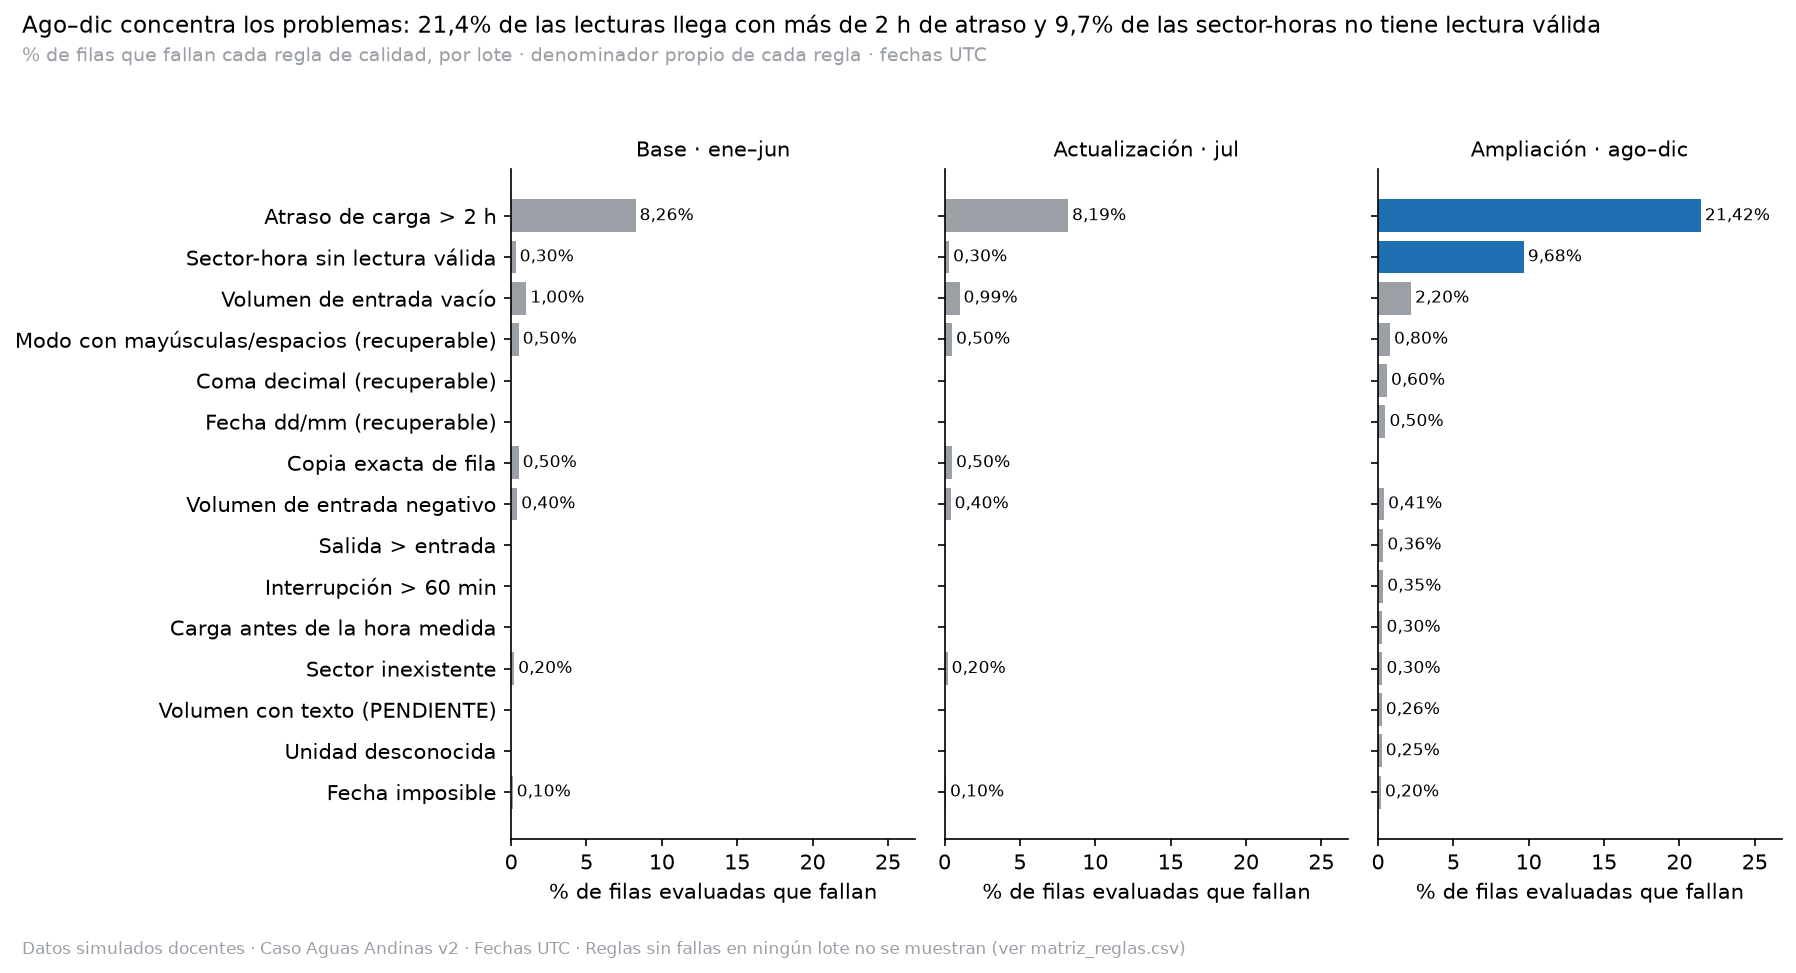

In [6]:
display(Image(filename=str(FIGURAS / "T2_reglas_por_lote.png"), width=980))

**Observación:** el atraso de carga y las sector-horas sin lectura válida son los problemas más extendidos, y ambos se agravan en ago–dic (21,4% y 9,7%). Ago–dic trae además 7 tipos de defecto que no existían en ene–jul. **Hipótesis:** otro proceso de captura en ago–dic; no es verificable. **Decisión:** reportar los KPI de ago–dic con su cobertura. **Límite:** cada barra tiene su propio denominador, así que no se suman.

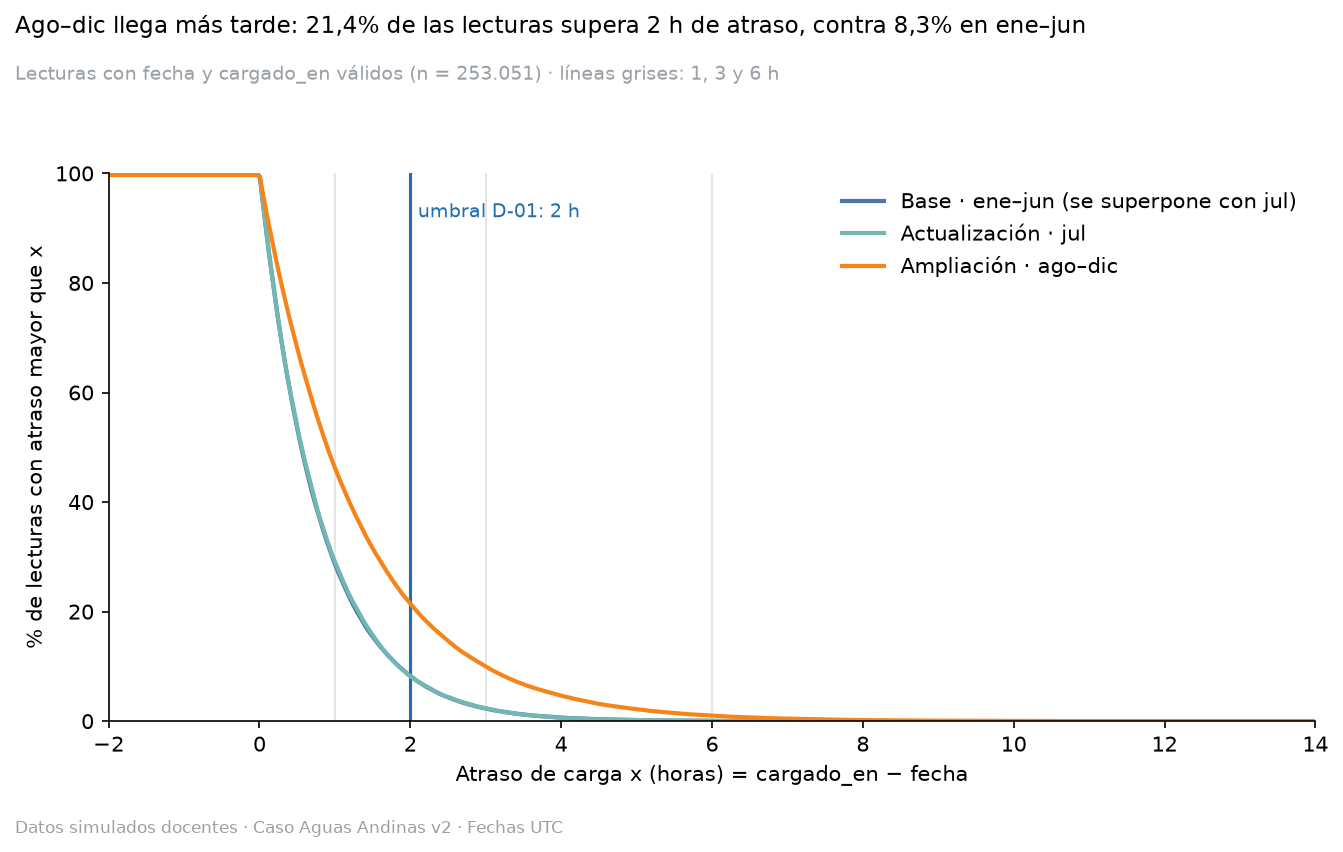

In [7]:
display(Image(filename=str(FIGURAS / "T2_atraso_carga.png"), width=980))

**Observación:** el 21,4% de las lecturas de ago–dic supera 2 h de atraso, contra 8,3% en ene–jun, y ago–dic es peor con cualquier umbral. **Límite:** el % exacto depende de interpretar `"latency": 2` como horas (D-01).

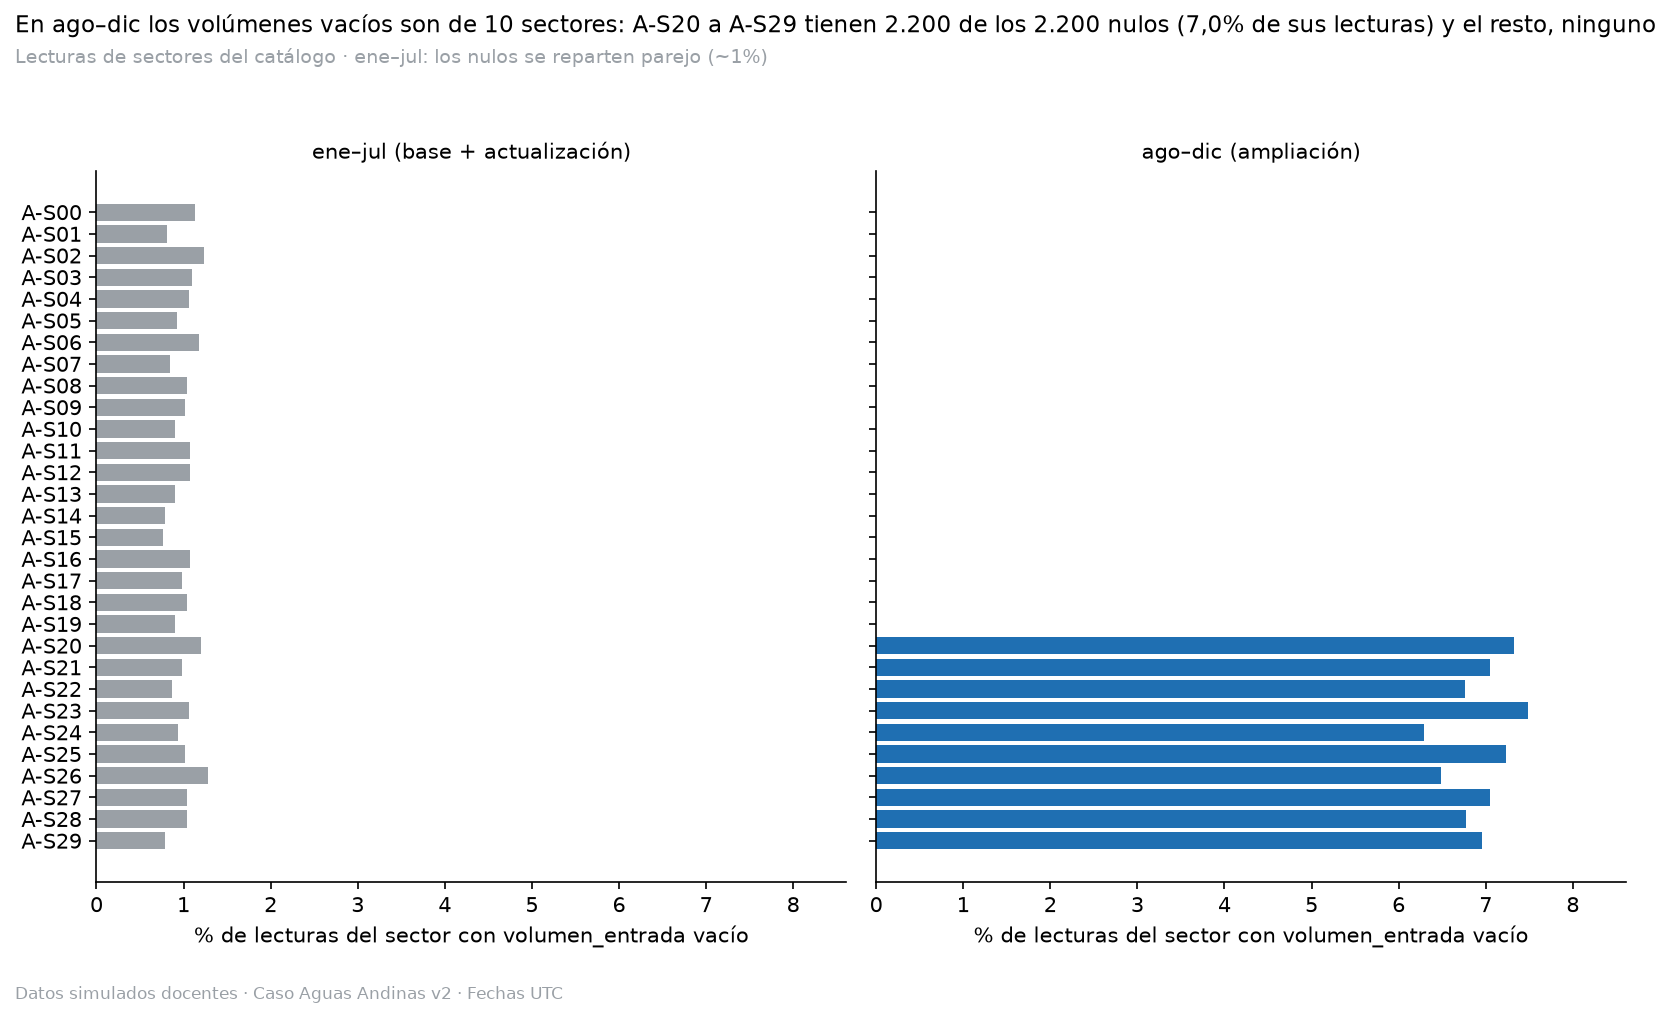

In [8]:
display(Image(filename=str(FIGURAS / "T2_nulos_por_sector.png"), width=980))

**Observación:** los 2.200 volúmenes de entrada vacíos de ago–dic están todos en A-S20 a A-S29 (6,95% de sus lecturas); en ene–jul se reparten parejo (≈ 1%). **Decisión:** si estos sectores se priorizan, se inspecciona primero el sensor ([D-02](decisiones.md)).

In [9]:
sesgo = rq.sesgo_kpi(df, ev, ctx)
sesgo[sesgo.alcance.eq("total")].pivot_table(index="escenario", columns="kpi", values="valor", sort=False).round(4)

kpi,diferencia_volumenes_pct,kwh_por_m3,continuidad_simple_pct
escenario,,,
Referencia (tratamiento correcto),16.1042,0.2651,98.3933
Sin convertir litros a m3,16.3605,0.0015,98.3933
Sin deduplicar copias exactas,16.1001,0.2652,98.3938
Incluyendo entrada negativa y salida > entrada,15.3330,0.2673,98.3933
Incluyendo minutos > 60,16.1042,0.2651,98.1869
Horas sin lectura tratadas como 0 min de interrupción,NaN,NaN,98.4634


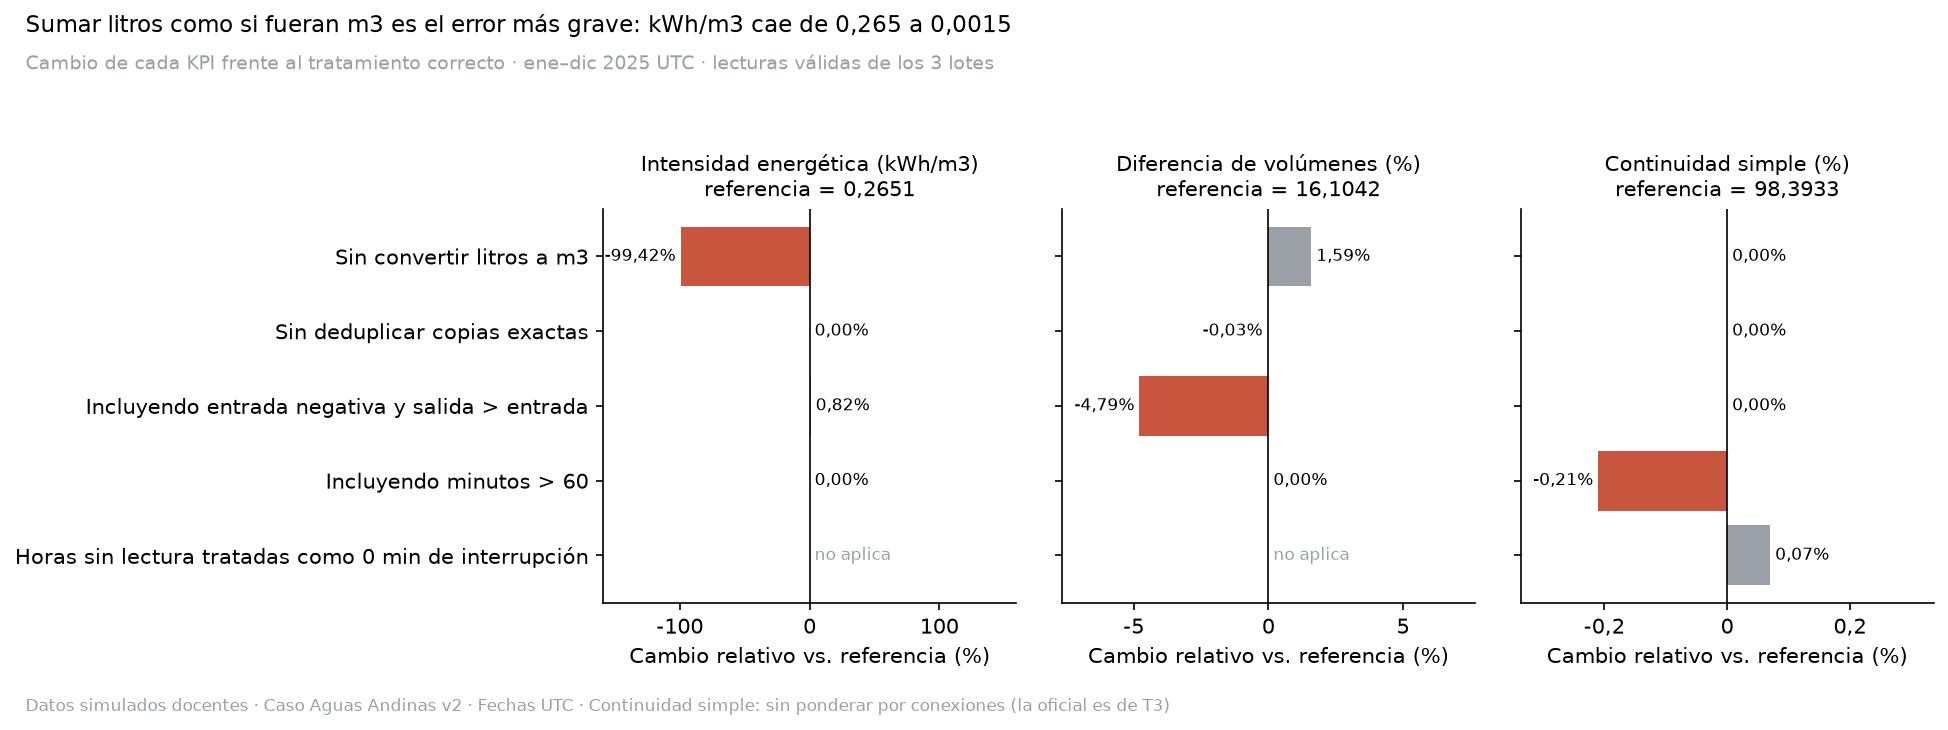

In [10]:
display(Image(filename=str(FIGURAS / "T2_sesgo_kpi.png"), width=980))

**Qué KPI sufren más sesgo:**
- Sumar litros como m³ hunde la intensidad energética en un 99,4%.
- Incluir las entradas negativas y salida > entrada baja la diferencia de volúmenes de 16,1% a 15,3%.
- La continuidad cambia décimas de punto, lo que importa frente a una meta de 99,5%.

## 5. Cobertura y continuidad con límites 0/60 (T3)

**Grilla esperada:** calendario UTC × 30 sectores (262.800 sector-horas), con un left join a las lecturas válidas. Las horas ausentes quedan visibles.

**Continuidad:** está ponderada por las conexiones vigentes en cada hora (cambian el 2025-10-01). Para las horas desconocidas se calculan dos escenarios extremos: 0 min de corte (límite superior) y 60 min de corte (límite inferior).

In [11]:
grilla = t3.construir_grilla(df, ctx, ev)
tablas3 = t3.generar_tablas(df, ctx, ev, grilla)
print(t3.validar_resultados(df, ctx, ev, grilla, tablas3))
display(tablas3["comparacion_lotes"][["lote", "horas_esperadas", "filas_recibidas", "horas_observadas", "horas_ausentes", "cobertura_pct"]].round(2))
cont = tablas3["continuidad_sector_ago_dic"]
cont[["sector_id", "cobertura_pct", "continuidad_obs_pct", "continuidad_min_pct", "continuidad_max_pct", "estado_meta"]].sort_values("cobertura_pct").round(2).head(8)

OK: hashes, grilla, T2, exposiciones, semanas, vigencias y contrato del ranking.


,lote,horas_esperadas,filas_recibidas,horas_observadas,horas_ausentes,cobertura_pct
0,actualizacion,22320,22432,22253,67,99.70
1,ampliacion,110160,100000,99500,10660,90.32
2,base,130320,130972,129929,391,99.70


,sector_id,cobertura_pct,continuidad_obs_pct,continuidad_min_pct,continuidad_max_pct,estado_meta
29,A-S29,75.71,97.02,72.51,97.77,bajo la meta
26,A-S26,75.79,96.84,72.43,97.64,bajo la meta
28,A-S28,76.17,96.76,72.68,97.56,bajo la meta
27,A-S27,76.88,96.71,73.33,97.50,bajo la meta
18,A-S18,91.72,98.74,90.23,98.85,bajo la meta
19,A-S19,91.86,98.54,90.29,98.67,bajo la meta
15,A-S15,91.88,98.87,90.45,98.97,bajo la meta
6,A-S06,91.94,98.76,90.51,98.86,bajo la meta


In [12]:
tablas3["uniones"]

,union,universo,hechos_evaluados,coincidencias_0,coincidencias_1,coincidencias_multiples,no_evaluables,fuera_alcance
0,lectura_catalogo,253404,253404,609,252795,0,0,0
1,lectura_historial,253404,253051,609,252442,0,353,0
2,grilla_historial,262800,262800,0,262800,0,0,0
3,lectura_tarifas_ago_dic,253404,99800,300,99500,0,353,153251
4,grilla_metas_anuales,262800,262800,0,262800,0,0,0


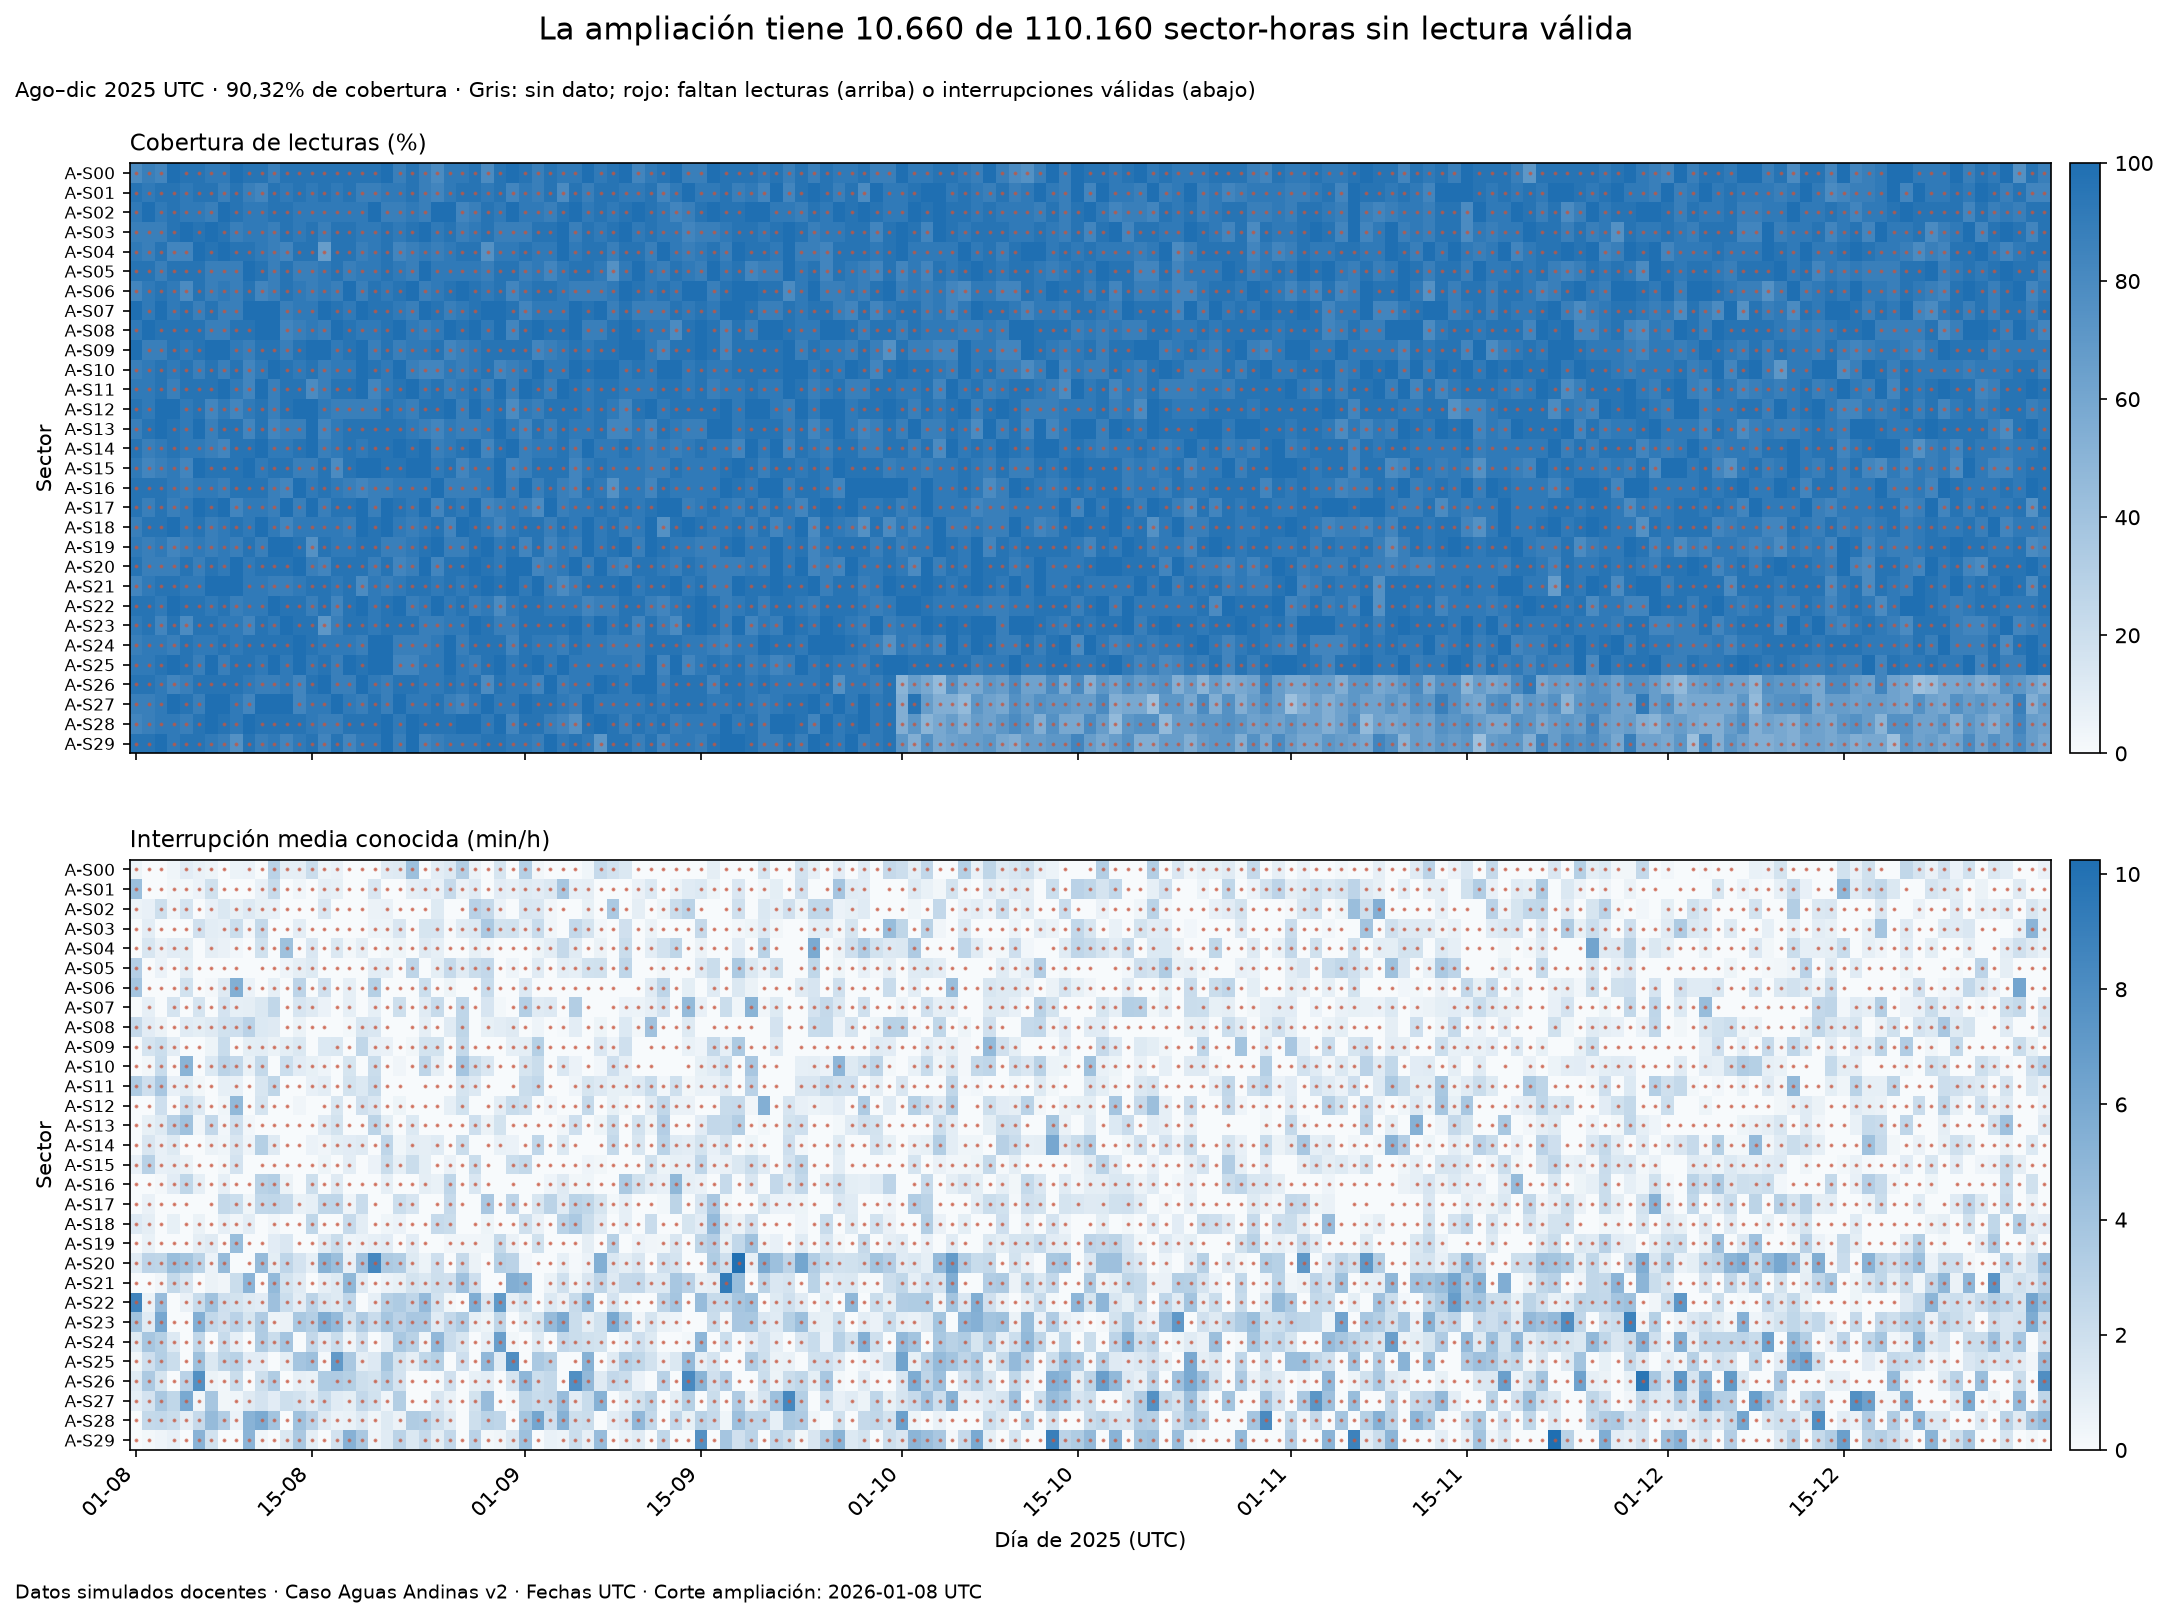

In [13]:
display(Image(filename=str(FIGURAS / "T3_cobertura_interrupciones.png"), width=980))

**Observación:** ago–dic tiene 10.660 de 110.160 sector-horas sin lectura válida. A-S26 a A-S29 reúnen 3.505 de ellas, con 76% de cobertura. **Decisión:** acompañar sus KPI con la cobertura y aplicar un filtro de cobertura en el ranking. **Límite:** no se conoce el estado de las horas faltantes.

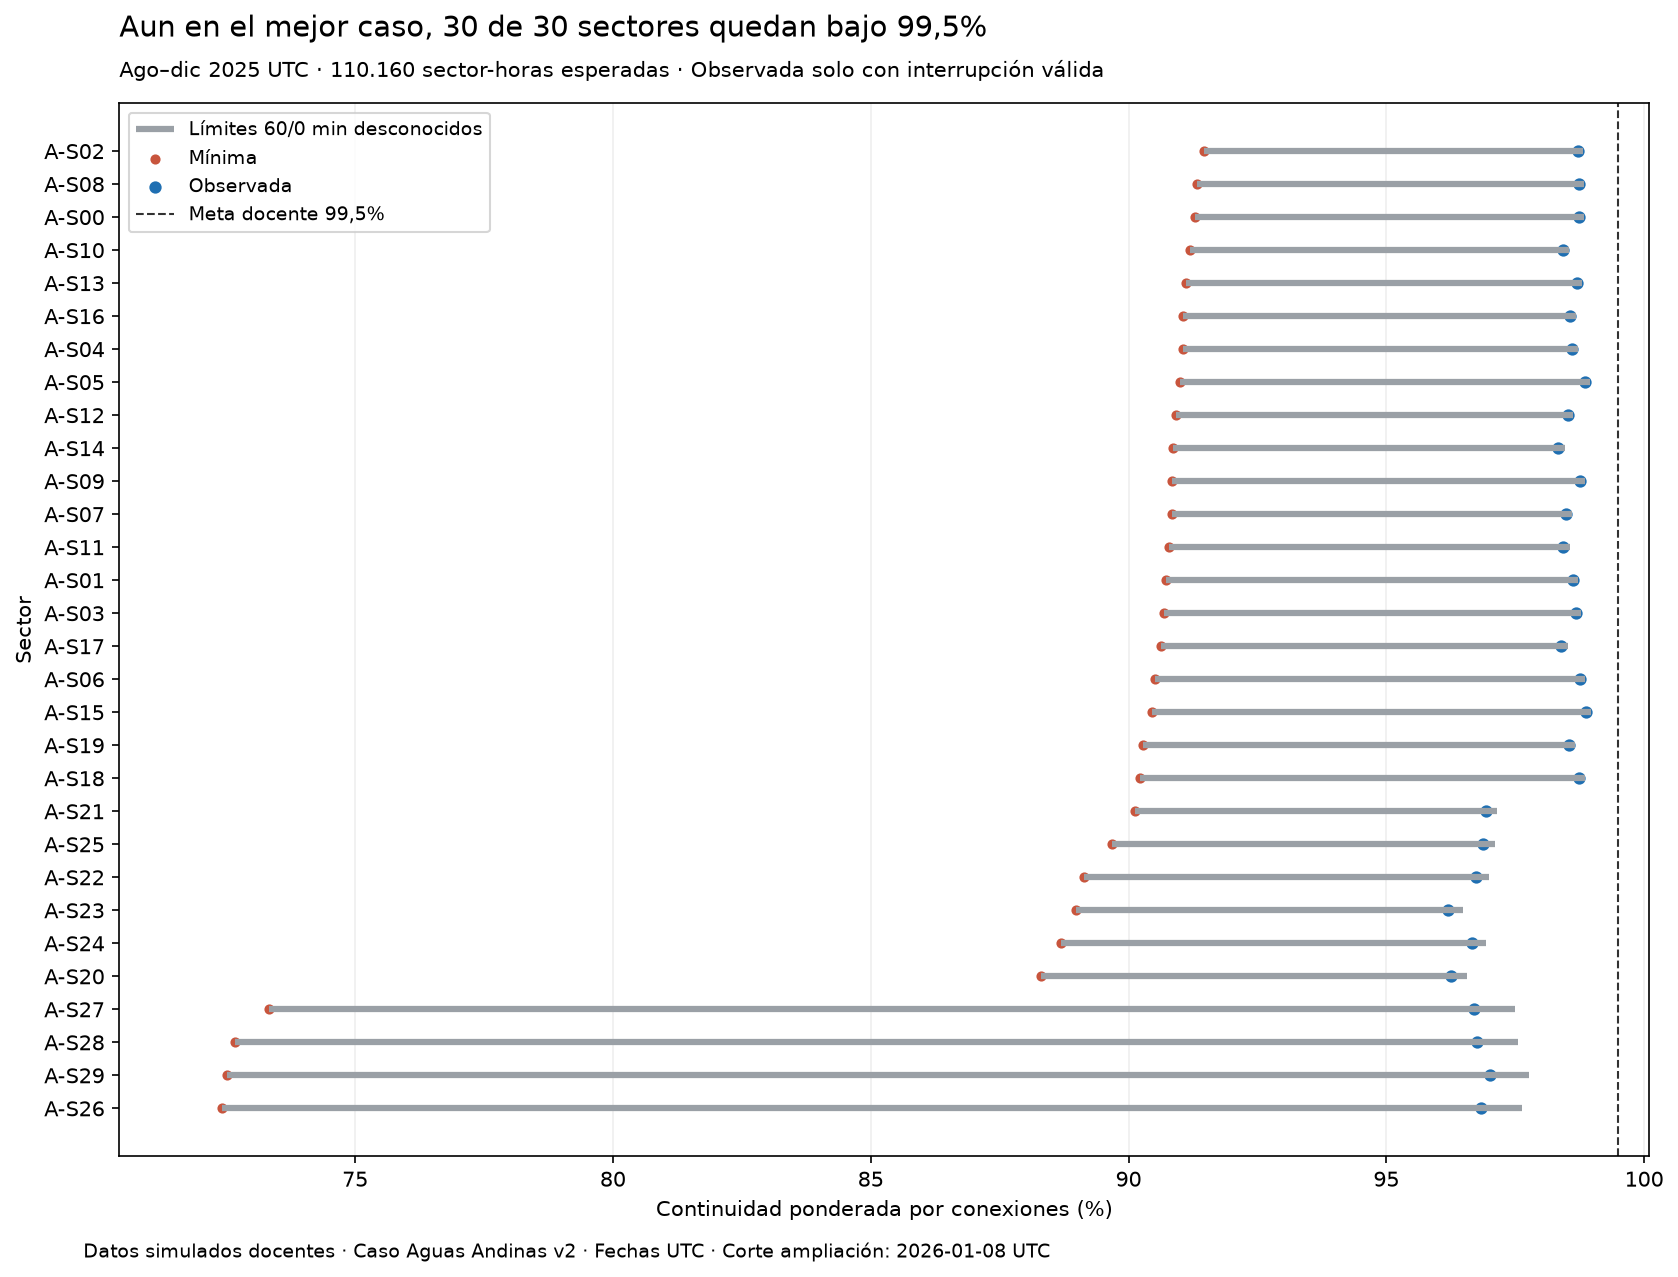

In [14]:
display(Image(filename=str(FIGURAS / "T3_continuidad_limites.png"), width=980))

**Observación:** aun suponiendo 0 min de corte en las horas desconocidas, los 30 sectores quedan bajo 99,5% (máximos de 96,5% a 99,0%). La meta no distingue sectores, así que la priorización usa posiciones relativas. **Límite:** los límites 0/60 son escenarios, no probabilidades.

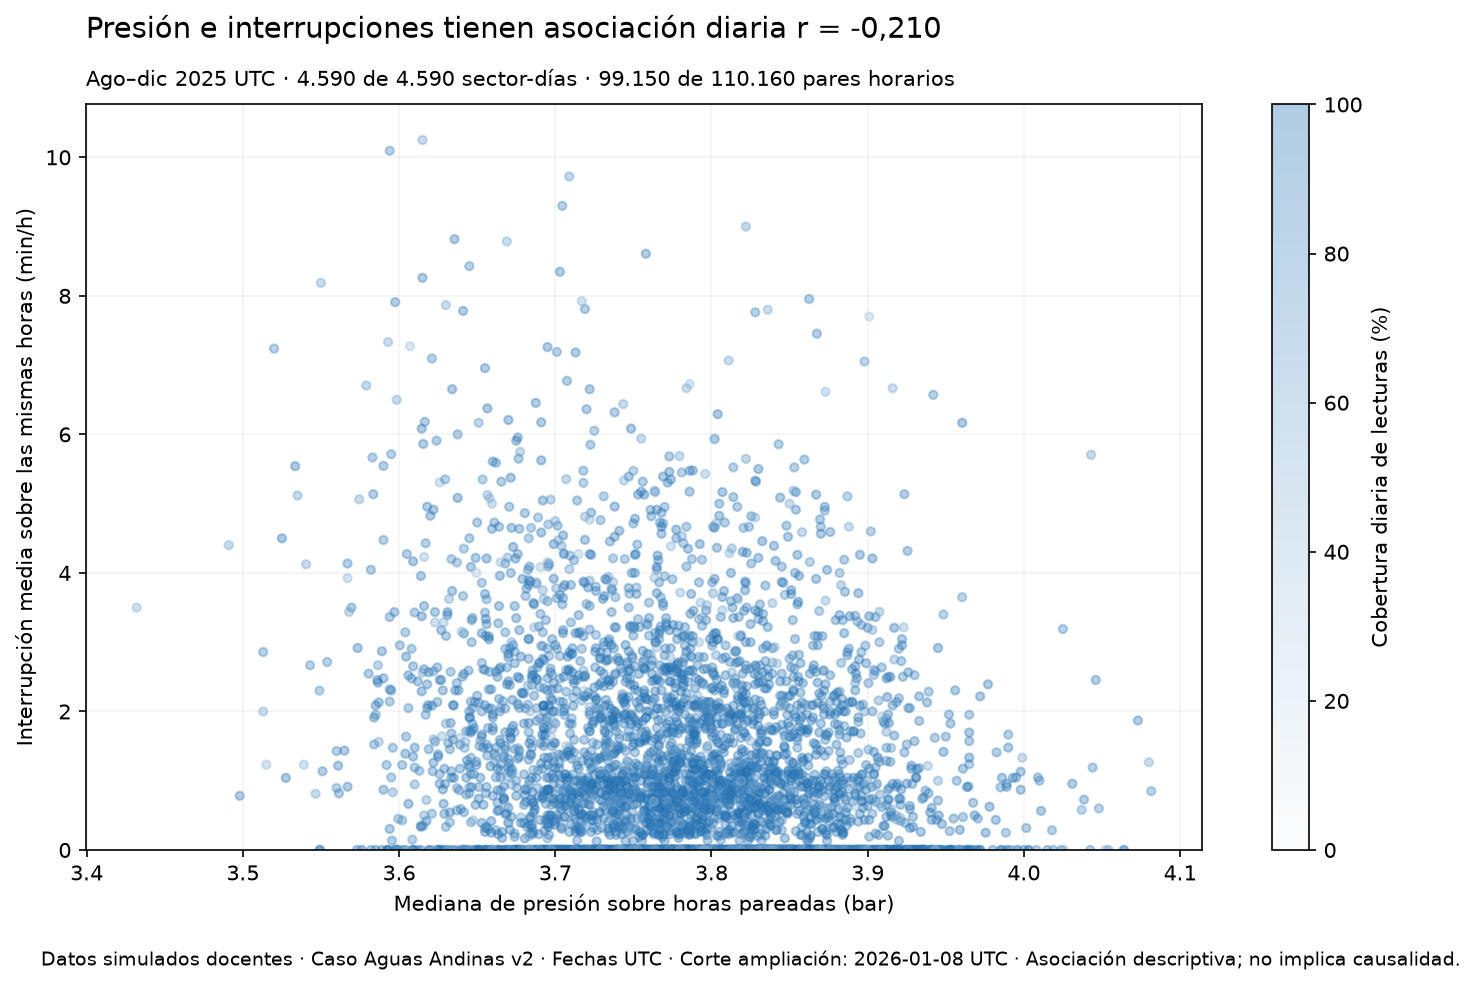

In [15]:
display(Image(filename=str(FIGURAS / "T3_presion_interrupciones.png"), width=980))

**Observación:** la asociación diaria entre presión e interrupciones es inversa (r = −0,21), calculada sobre las mismas horas válidas. **Límite:** es una asociación descriptiva, no causal; una presión baja es solo una señal operacional.

## 6. Análisis exploratorio de negocio (T4)

Todo se calcula sobre lecturas válidas, con volúmenes en m³ (los litros se dividen por 1000; una unidad desconocida no se convierte). Las exclusiones se declaran con su cantidad y su denominador.

In [16]:
t4.exclusiones(df)

,poblacion,concepto,n,denominador,pct
0,ene–dic 2025,Lecturas válidas (denominador),251682,251682,100.000
1,ene–dic 2025,Volumen de entrada no convertible (unidad desc...,250,251682,0.099
2,ene–dic 2025,Volumen de entrada nulo o PENDIENTE (unidad co...,3976,251682,1.580
3,ene–dic 2025,Volumen de salida no convertible,0,251682,0.000
4,ene–dic 2025,Volumen de entrada negativo,1010,251682,0.401
5,ene–dic 2025,Salida mayor que entrada,350,251682,0.139
6,ene–dic 2025,Minutos de interrupción fuera de 0–60,350,251682,0.139
7,ene–dic 2025,Lecturas que entran a vol_ok (volúmenes),246096,251682,97.781
8,ago–dic 2025,Lecturas válidas (denominador),99500,99500,100.000
9,ago–dic 2025,Volumen de entrada no convertible (unidad desc...,250,99500,0.251


In [17]:
display(t4.distribucion(df).round(3))
pd.Series(t4.proporcion_interrupcion(df)).round(3)

,variable,n,media,mediana,p25,p75,ric,min,max
0,volumen_entrada_m3 (m3 por hora),246096,603.956,592.662,318.587,839.752,521.165,155.676,1390.092
1,diferencia entrada − salida (m3 por hora),246096,97.262,81.074,47.012,133.817,86.805,5.941,444.887
2,presion_bar,251682,3.773,3.787,3.575,3.994,0.419,1.100,5.308
3,energia_kwh (por hora),251682,160.208,159.289,86.628,222.144,135.516,34.500,376.317
4,minutos_interrupcion (solo horas con 0–60),251332,0.964,0.000,0.000,0.000,0.000,0.000,60.000


n                       251332.000
sin_interrupcion        240530.000
con_interrupcion         10802.000
pct_con_interrupcion         4.298
mediana_si_hay              19.000
p90_si_hay                  48.000
dtype: float64

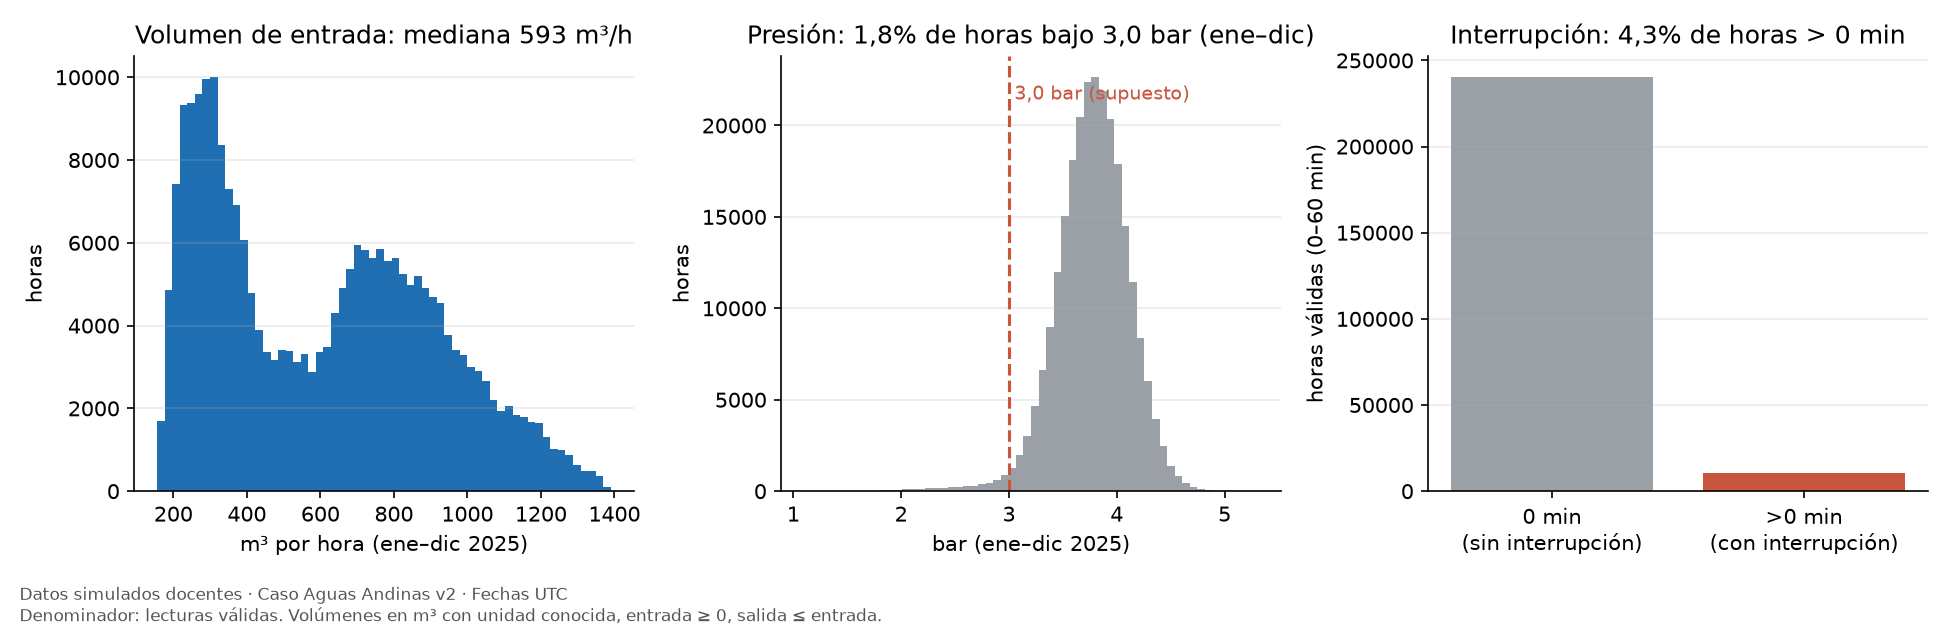

In [18]:
display(Image(filename=str(FIGURAS / "T4_a_distribucion.png"), width=980))

**(a) Distribución:** el volumen de entrada tiene mediana de 593 m³/h. El 4,3% de las horas válidas tiene interrupción > 0. **Cero ≠ nulo:** 0 min es una lectura observada, mientras que un volumen vacío significa "no se sabe".

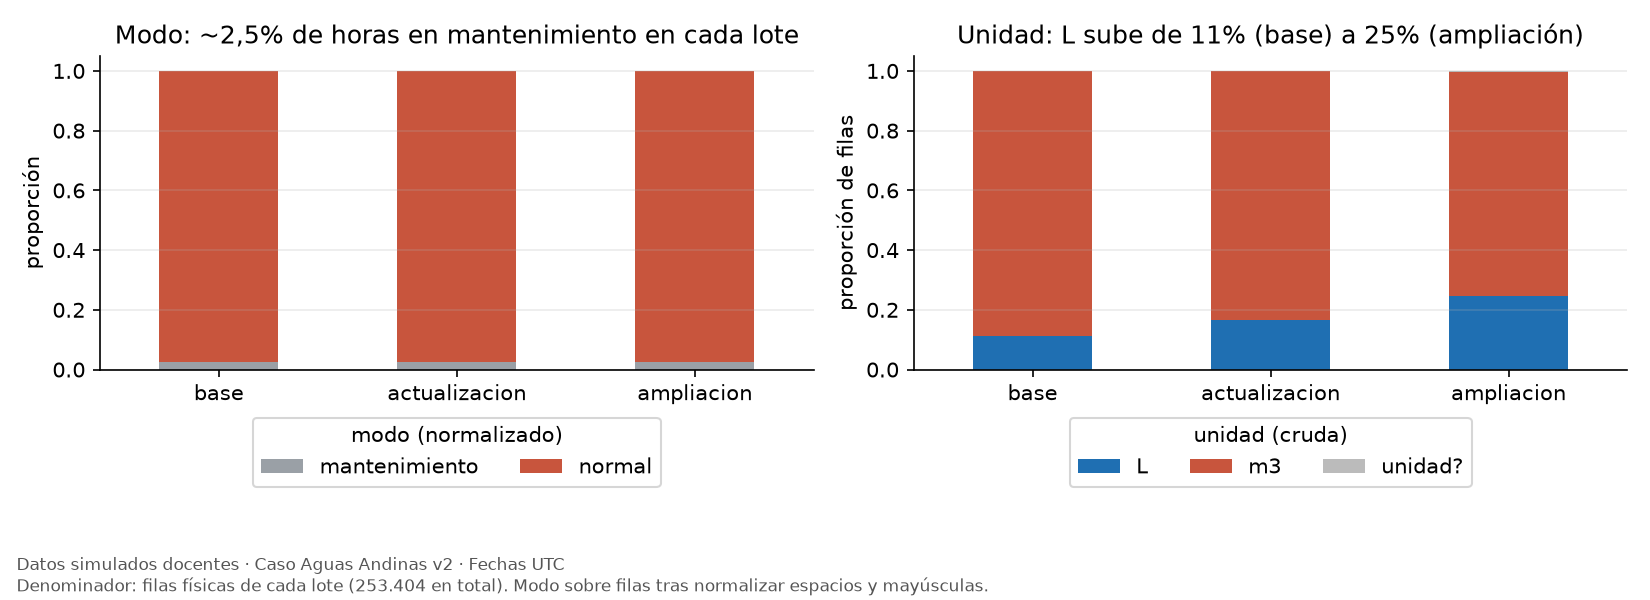

In [19]:
display(Image(filename=str(FIGURAS / "T4_b_categorias.png"), width=980))

**(b) Categorías:** cerca de 2,5% de las horas están en mantenimiento en cada lote. La proporción de lecturas en litros sube de 11% (base) a 25% (ampliación), lo que obliga a convertir antes de sumar.

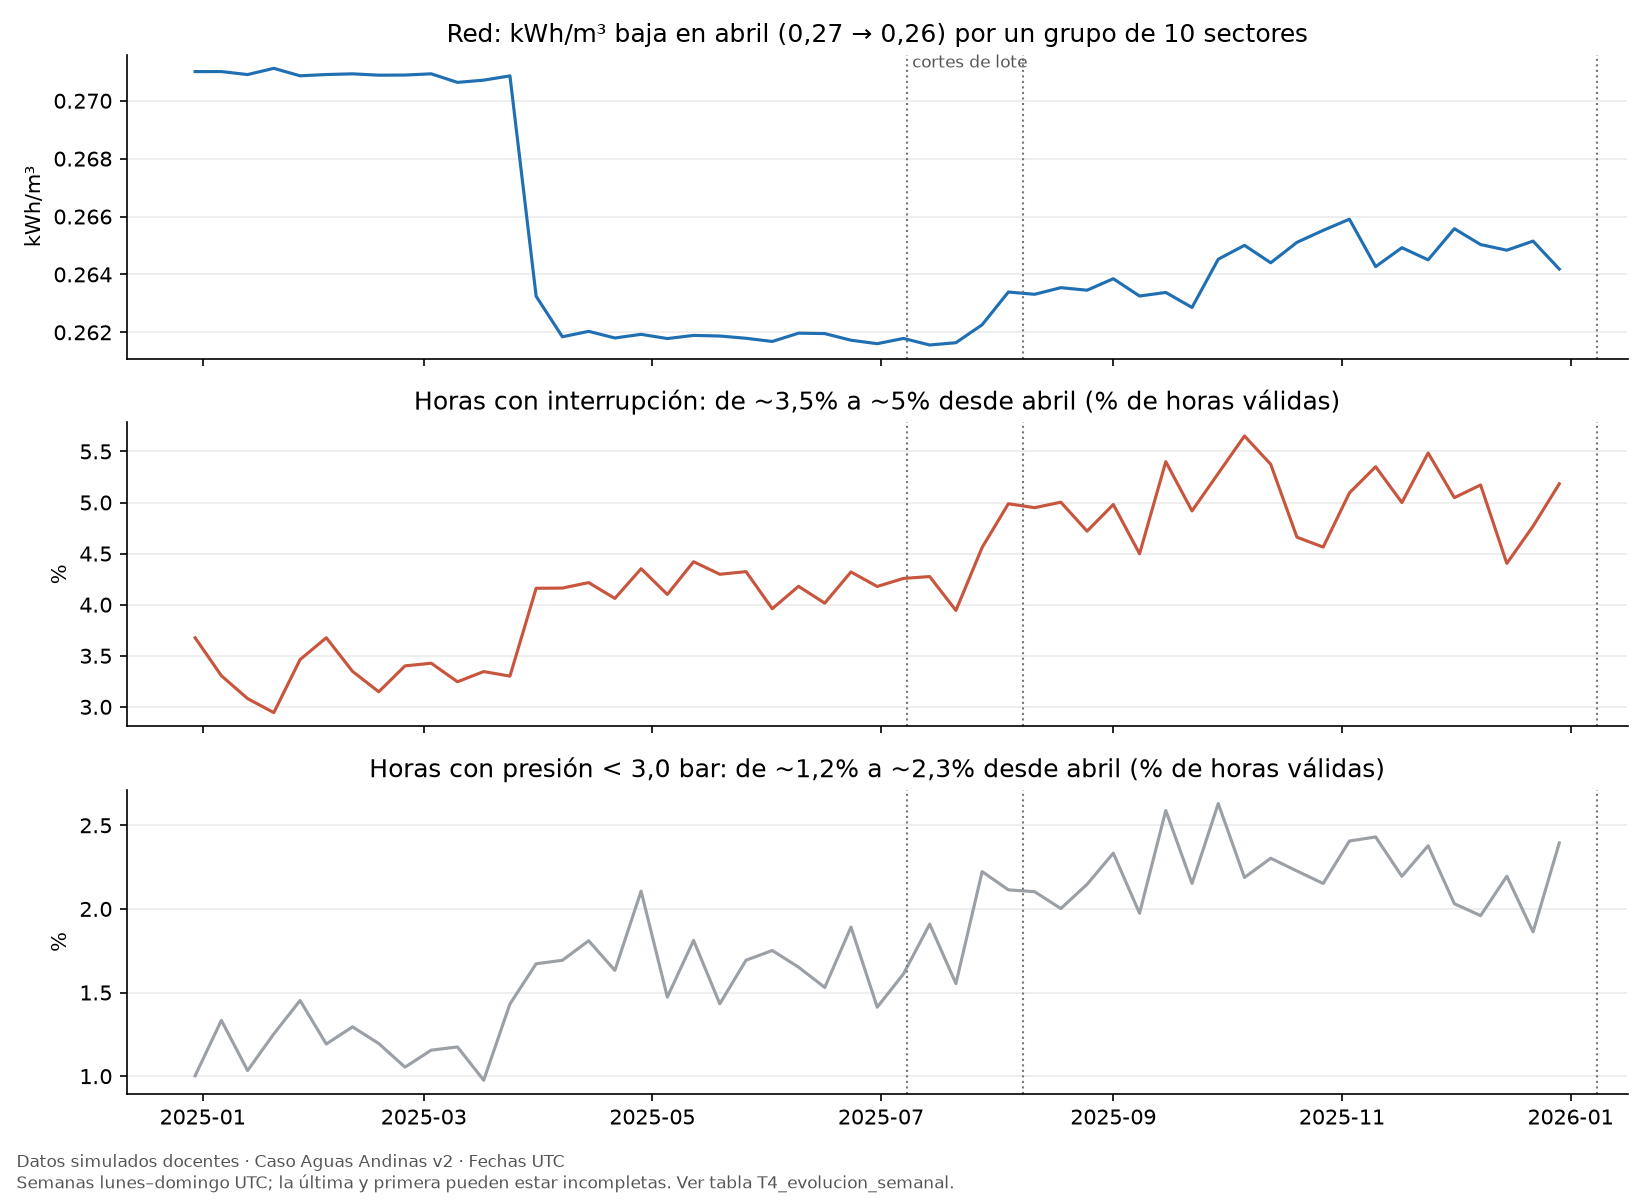

In [20]:
display(Image(filename=str(FIGURAS / "T4_c_evolucion.png"), width=980))

**(c) Evolución temporal:** desde abril baja el kWh/m³ de la red y suben las horas con interrupción y con presión < 3,0 bar ([D-08](decisiones.md), supuesto docente). Las líneas punteadas marcan los cortes de lote.

In [21]:
t4.comparar_segmentos(df).round(3)

,modo_operacion,horas_validas,horas_con_volumen_ok,kwh_por_m3,dif_volumen_pct,presion_mediana_bar,pct_horas_con_interrupcion,horas_con_interrupcion
0,mantenimiento,6215,6066,0.264,16.138,3.366,100.000,6206
1,normal,245467,240030,0.265,16.103,3.794,1.875,4596


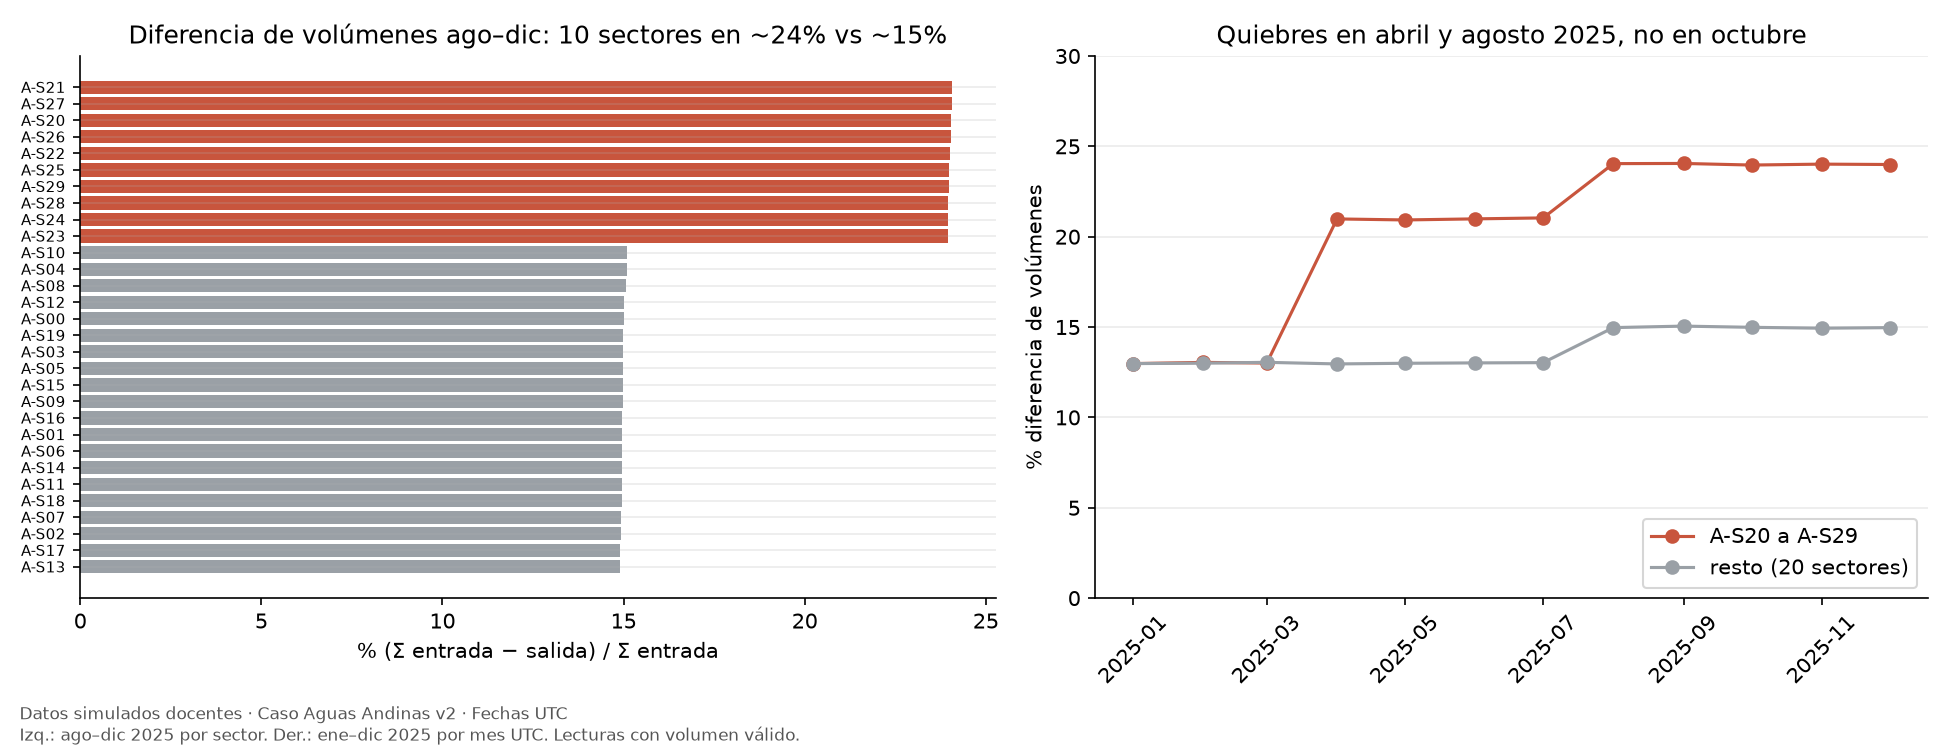

In [22]:
display(Image(filename=str(FIGURAS / "T4_d_segmentos.png"), width=980))

**(d) Segmentos:** en ago–dic, A-S20 a A-S29 pierden el 24% del volumen de entrada, contra 15% del resto, tanto en m³ como en L, con quiebres en abril y agosto. Las horas de mantenimiento tienen interrupción el 100% de las veces. **Hipótesis:** un cambio de medición o una pérdida real; los datos no permiten separarlos.

In [23]:
t4.correlaciones(df).round(3)

,par,n,pearson,spearman
0,energia_kwh vs volumen_entrada_m3,246096,0.960,0.968
1,presion_bar vs diferencia entrada − salida (m3),246096,-0.018,-0.007


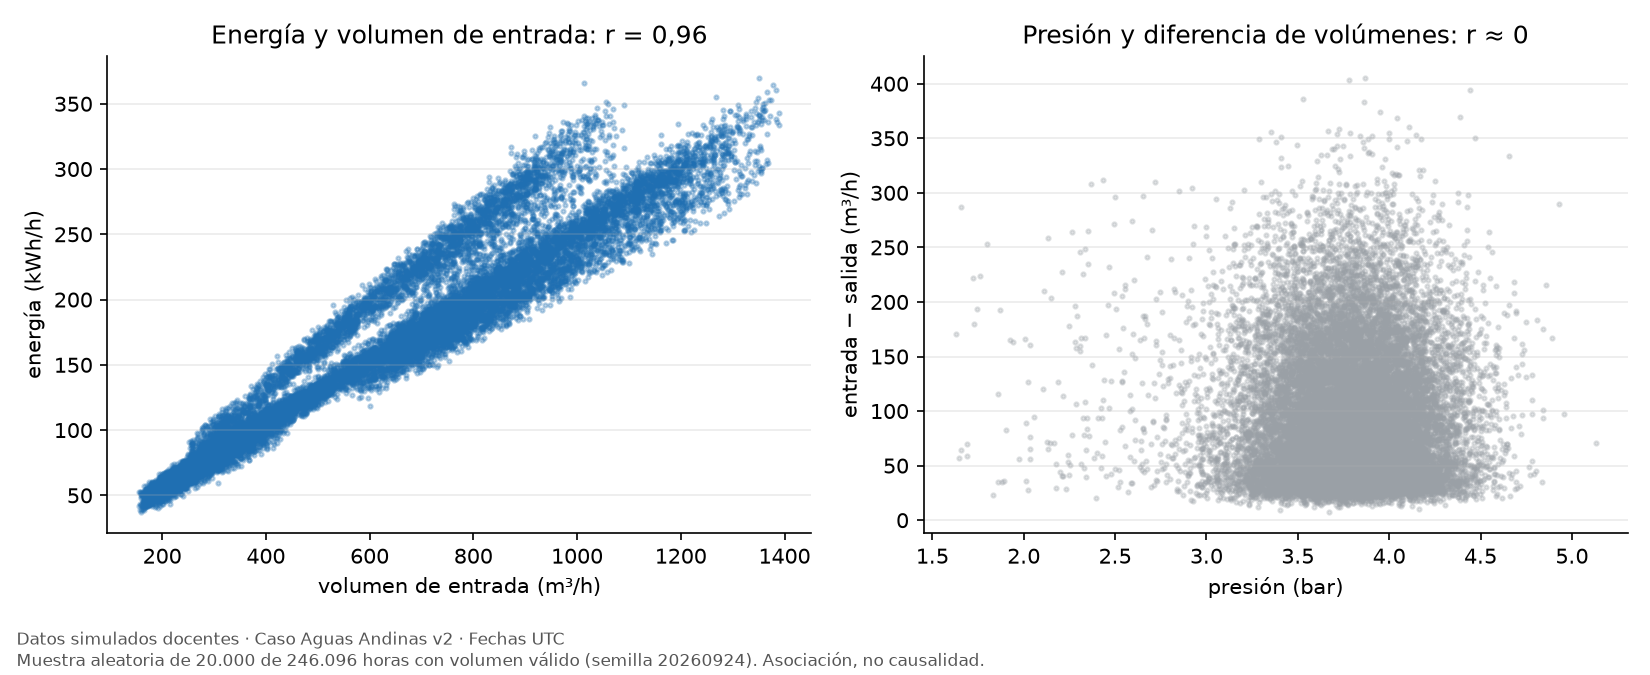

In [24]:
display(Image(filename=str(FIGURAS / "T4_e_bivariada.png"), width=980))

**(e) Relación bivariada:** la energía y el volumen de entrada tienen r = 0,96, una relación esperable. La presión y la diferencia de volúmenes no están asociadas (r ≈ 0). La correlación se calcula solo entre variables interpretables.

## 7. Costo de energía por m³ (T4)

In [25]:
costo = t4.costo_m3(df, ctx)
costo[["clave", "costo_clp_por_m3", "costo_clp_por_m3_promedio_razones_horarias", "costo_clp_por_m3_sin_convertir_litros",
       "kwh_por_m3", "tarifa_clp_kwh_ponderada", "efecto_energia_clp_m3", "efecto_tarifa_clp_m3"]].round(3)

,clave,costo_clp_por_m3,costo_clp_por_m3_promedio_razones_horarias,costo_clp_por_m3_sin_convertir_litros,kwh_por_m3,tarifa_clp_kwh_ponderada,efecto_energia_clp_m3,efecto_tarifa_clp_m3
0,2025-08,34.893,35.530,0.200,0.263,132.490,0.000,0.000
1,2025-09,36.200,36.882,0.208,0.263,137.479,-0.006,1.314
2,2025-10,37.734,38.382,0.126,0.265,142.424,0.209,2.632
3,2025-11,39.063,39.724,0.132,0.265,147.410,0.217,3.954
4,2025-12,40.398,41.086,0.135,0.265,152.413,0.224,5.281
5,ago–dic,37.612,38.281,0.152,0.264,142.299,NaN,NaN


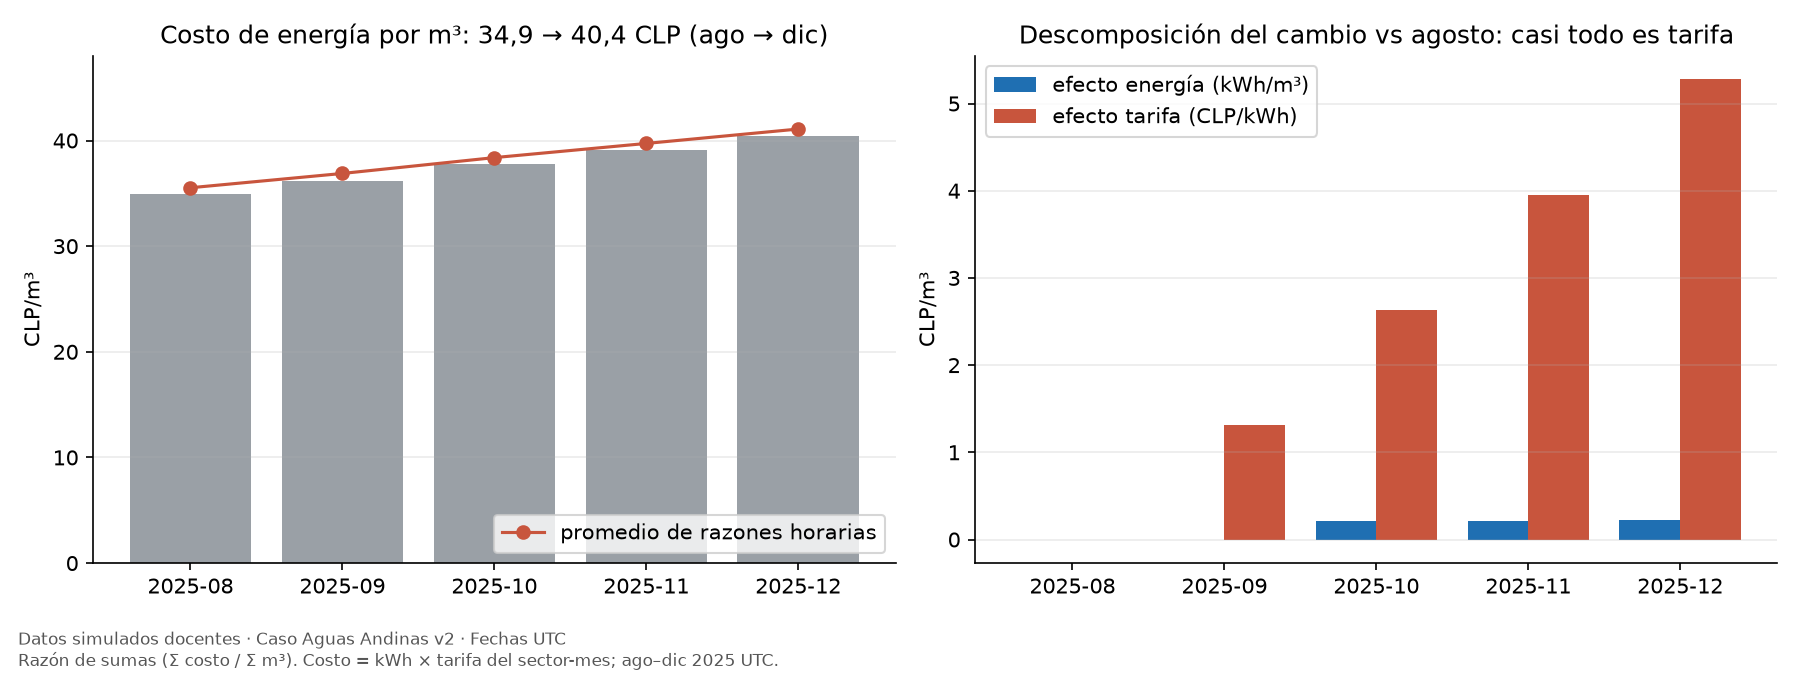

In [26]:
display(Image(filename=str(FIGURAS / "T4_costo_m3.png"), width=980))

**Observación:**
- El costo sube de 34,9 a 40,4 CLP/m³ entre agosto y diciembre, y el 96% del alza es tarifa.
- La razón de sumas da 37,61 CLP/m³ y el promedio de razones horarias, 38,28. El KPI usa la razón de sumas ([D-09](decisiones.md)).
- Sin convertir litros, el costo daría 0,15 CLP/m³.

## 8. KPI y métricas de calidad (T4 + T2)

In [27]:
kpi = pd.Series(t4.kpi_valores(df, ctx), name="valor ago–dic")
display(kpi.to_frame())
kri = rq.valores_kri(matriz)
display(kri)
fichas = pd.read_csv(TABLAS / "fichas_indicadores.csv")
fichas[["id", "tipo_KPI_KRI_visual", "formula", "denominador", "umbral", "accion"]]

,valor ago–dic
"KPI-01 continuidad (T3, sectores bajo meta con límite superior)",30.000000
KPI-02 diferencia de volúmenes (%),18.181472
KPI-03 intensidad energética (kWh/m3),0.264315
KPI-04 costo de energía (CLP/m3),37.611734
KPI-05 horas con interrupción (%),5.015633
KPI-06 horas con presión baja (%),2.220101
"KPI-06 sensibilidad 2,5 bar (%)",0.735678
"KPI-06 sensibilidad 3,5 bar (%)",18.778894
denominador KPI-02/03/04 (lecturas con volumen válido),96050.000000
"denominador KPI-05 (horas válidas con minutos en 0–60, ago–dic)",99150.000000


,id,metrica,numerador,denominador,valor_pct
0,KRI-01,Cobertura de lecturas válidas,251682,262800,95.769
1,KRI-02,Unicidad de clave (copias),764,253404,0.301
2,KRI-03,Unidad desconocida,250,253404,0.099
3,KRI-04,Salida > entrada,350,248160,0.141
4,KRI-05,"Minutos fuera de [0, 60]",350,253404,0.138
5,KRI-06,Lecturas con atraso > 2 h,34016,253051,13.442


,id,tipo_KPI_KRI_visual,formula,denominador,umbral,accion
0,KPI-01,KPI,Observada = 100 × (1 − min. interrumpidos / mi...,Minutos de conexión esperados = Σ conexiones v...,"99,5","Si el límite superior queda bajo la meta, el s..."
1,KPI-02,KPI,100 × Σ(entrada − salida) / Σ entrada (razón d...,Σ volumen_entrada_m3 en las mismas lecturas,sin meta docente,Sectores con mayor diferencia: revisar medició...
2,KPI-03,KPI,Σ energia_kwh / Σ volumen_entrada_m3,Σ volumen_entrada_m3 en las mismas lecturas,sin meta docente,Sectores con kWh/m3 alto frente al resto: revi...
3,KPI-04,KPI,Σ (energia_kwh × tarifa_kwh_clp) / Σ volumen_e...,Σ volumen_entrada_m3 en las mismas lecturas,sin meta docente,Separar si el costo sube por energía (kWh/m3) ...
4,KPI-05,KPI,100 × horas observadas con minutos_interrupcio...,"Horas observadas válidas (minutos en [0, 60])",sin meta docente,Sectores con frecuencia alta: cruzar con conti...
5,KPI-06,KPI,100 × horas observadas válidas con presion_bar...,Horas observadas válidas,"3,0 bar (supuesto docente; sensibilidad 2,5 y ...",Concentraciones de presión baja: revisar telem...
6,KRI-01,KRI,100 × sector-horas con lectura válida / sector...,Sector-horas esperadas = horas del período del...,≥ 95% por sector (propuesta a validar en E3),"Bajo el umbral, el sector no se califica solo ..."
7,KRI-02,KRI,100 × filas que son copia exacta de otra con e...,Filas de telemetría del lote,0%,"Si es > 0%, deduplicar antes de calcular cualq..."
8,KRI-03,KRI,100 × filas con unidad_volumen distinta de m3 ...,Filas de telemetría del lote,0%,"Si es > 0%, excluir esos volúmenes y pedir la ..."
9,KRI-04,KRI,100 × filas con volumen_salida > volumen_entra...,"Filas con ambos volúmenes numéricos, unidad co...",0% (el modelo omite almacenamiento y transfere...,"Si es > 0%, excluir esas horas de la diferenci..."


## 9. Ranking de inspección (T2 + T3 + T4)

- **Puntaje:** promedio de los percentiles de continuidad, diferencia de volúmenes y energía.
- **Tipo de inspección:** la confiabilidad del dato decide si se revisa el sensor primero o la operación ([D-02](decisiones.md)).
- **Filtro elegido:** cobertura ≥ 80%, que excluye solo a A-S26 a A-S29 (≈ 76%).

In [28]:
t2_sector = rq.por_sector(df, ev, ctx)
rankings = rq.comparar_rankings(t2_sector, tablas3["por_sector"], t4.por_sector(df, ctx))
cols = ["posicion", "sector_id", "puntaje", "p_continuidad", "p_diferencia", "p_energia", "cobertura_pct",
        "dif_volumen_pct", "kwh_por_m3", "pct_filas_con_defecto", "tipo_inspeccion"]
print("Sectores elegibles por filtro:", rankings.groupby("filtro_cobertura", sort=False).size().to_dict())
for filtro in ["sin filtro", "cobertura ≥ 80%"]:
    print("\n" + filtro)
    display(rankings[rankings.filtro_cobertura.eq(filtro)][cols].head(5).round(3))

Sectores elegibles por filtro: {'sin filtro': 30, 'cobertura ≥ 80%': 26, 'cobertura ≥ 85%': 26, 'cobertura ≥ 90%': 26}

sin filtro


,posicion,sector_id,puntaje,p_continuidad,p_diferencia,p_energia,cobertura_pct,dif_volumen_pct,kwh_por_m3,pct_filas_con_defecto,tipo_inspeccion
0,1,A-S20,0.878,0.967,0.933,0.733,92.048,24.044,0.29,9.333,sensor primero
1,2,A-S25,0.822,0.767,0.833,0.867,92.810,23.980,0.304,9.104,sensor primero
2,3,A-S10,0.733,0.600,0.667,0.933,93.083,15.087,0.324,2.336,operación
3,4,A-S23,0.650,1.000,0.700,0.250,92.919,23.945,0.242,9.623,sensor primero
4,5,A-S27,0.644,0.900,0.967,0.067,76.879,24.065,0.227,8.814,sensor primero



cobertura ≥ 80%


,posicion,sector_id,puntaje,p_continuidad,p_diferencia,p_energia,cobertura_pct,dif_volumen_pct,kwh_por_m3,pct_filas_con_defecto,tipo_inspeccion
30,1,A-S20,0.872,0.962,0.962,0.692,92.048,24.044,0.29,9.333,sensor primero
31,2,A-S25,0.859,0.846,0.885,0.846,92.810,23.980,0.304,9.104,sensor primero
32,3,A-S10,0.795,0.692,0.769,0.923,93.083,15.087,0.324,2.336,operación
33,4,A-S23,0.660,1.000,0.808,0.173,92.919,23.945,0.242,9.623,sensor primero
34,5,A-S21,0.628,0.808,1.000,0.077,93.301,24.067,0.23,9.086,sensor primero


**Propuesta:**

| # | Sector | Por qué | Inspección |
|---|---|---|---|
| 1 | **A-S20** | Entre los peores en continuidad y en diferencia de volúmenes (24%) | Sensor primero (9,3% de lecturas con defecto) |
| 2 | **A-S25** | Alto en los tres criterios | Sensor primero (9,1%) |
| 3 | **A-S10** | La mayor energía por m³ (0,324 kWh/m³ vs. mediana de 0,263) | Operación (2,3%) |

Los 3 primeros no cambian con filtros de 80, 85 o 90%, y ningún sector alcanza 95%. A-S26 a A-S29 requieren primero recuperar su transmisión de datos.

**Límite:** los percentiles amplifican diferencias pequeñas entre sectores cercanos a 15% de diferencia de volúmenes.

## 10. Verificación cruzada de cifras (T5)

Si alguna cifra compartida entre tareas no cuadra, esta celda falla.

In [29]:
validas_t2 = rq.cobertura(df, ev, ctx).set_index("lote")["sector_horas_con_lectura_valida"]
assert validas_t2["ampliacion"] == int(tablas3["comparacion_lotes"].set_index("lote").loc["ampliacion", "horas_observadas"]) == 99500
assert int(df["ago_dic"].sum()) == 99500                                   # misma población de T4
guardado = pd.read_csv(TABLAS / "T2_ranking.csv")
for filtro in ["sin filtro", "cobertura ≥ 80%"]:
    nuevo = rankings[rankings.filtro_cobertura.eq(filtro)].head(3).sector_id.tolist()
    assert nuevo == guardado[guardado.filtro_cobertura.eq(filtro)].head(3).sector_id.tolist() == ["A-S20", "A-S25", "A-S10"]
assert len(fichas) == 12 and set(fichas.tipo_KPI_KRI_visual) == {"KPI", "KRI"}
assert (cont["continuidad_max_pct"] < 99.5).all()
comun.verificar_hashes()
print("OK: cobertura T2 = T3 = T4 (99.500), ranking reproducible, 12 fichas, 30 sectores bajo la meta, originales intactos.")

OK: cobertura T2 = T3 = T4 (99.500), ranking reproducible, 12 fichas, 30 sectores bajo la meta, originales intactos.
